# Modelo Supervisado
## Predicción de mantenimiento correctivo en camiones

Este notebook corresponde a la etapa de aprendizaje supervisado del proyecto.

A partir del análisis exploratorio realizado anteriormente, se buscará construir un modelo de clasificación capaz de anticipar la ocurrencia de mantenimiento correctivo en los equipos.

El objetivo será utilizar información histórica disponible de cada camión para predecir si requerirá mantenimiento correctivo en el período siguiente.

Se entrenarán y compararán tres algoritmos de clasificación:

1. Regresión Logística.
2. Árbol de Decisión.
3. Random Forest.

Los modelos serán evaluados utilizando el mismo conjunto de prueba y diferentes métricas de clasificación para seleccionar la alternativa que presente mejor capacidad de generalización.

## 1. Definición del problema

El problema se plantea como una **clasificación binaria**.

Para cada equipo y período se buscará predecir si el camión requerirá mantenimiento correctivo durante el período siguiente:

- `0`: el equipo no requerirá mantenimiento correctivo.
- `1`: el equipo requerirá mantenimiento correctivo.

La predicción deberá realizarse utilizando únicamente información que estaría disponible antes del período que se intenta predecir.

Esta condición es fundamental para evitar fuga de información (`data leakage`) y simular correctamente un escenario real de mantenimiento predictivo.

## 2. Carga del dataset procesado

Se utiliza la versión procesada del dataset obtenida durante el análisis exploratorio, que contiene las transformaciones y correcciones realizadas previamente.

In [4]:
import pandas as pd

ruta = "../data/processed/dataset_registro_fallas_x_mes_CAMIONES_PROCESADO.csv"

df = pd.read_csv(
    ruta,
    sep=";",
    decimal=","
)

print("Dimensiones:", df.shape)

df.head()

Dimensiones: (7874, 37)


,ID,EQUIPO,PERIODO,SUBUN,REQUIRIO_MANT,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,...,HS_MES,KM_MES,RAL_MES,HSOPE_MES,TIPO_CHASIS,CAPACIDAD_TN,RUTINA_MANT,CONSUMO_HS,CONSUMO_KM,ANTIGUEDAD
0,C3_2024-01,C3,2024-01,DTM-02,NO,0,0,0,0,0,...,105.0,74.0,93.0,0.0,DM800,58.0,PETROLERO,4.05,5.13,15.0
1,C5_2024-01,C5,2024-01,DTM-02,NO,0,0,0,0,0,...,21.0,29.0,11.0,0.0,CON GUINCHE,58.0,PETROLERO,17.15,3.29,44.0
2,C8_2024-01,C8,2024-01,DTM-02,NO,0,0,0,0,0,...,29.0,106.0,23.0,0.0,DM800,58.0,PETROLERO,5.11,0.67,16.0
3,C14_2024-01,C14,2024-01,DTM-02,NO,0,0,0,0,0,...,245.0,173.0,226.0,0.0,DM32,58.0,PETROLERO,3.11,3.11,17.0
4,C16_2024-01,C16,2024-01,DTM-02,NO,0,0,0,0,0,...,56.0,277.0,42.0,0.0,DM800,45.0,PETROLERO,6.16,0.81,13.0


## 3. Definición de la variable objetivo

El problema se plantea como una clasificación binaria.

La variable objetivo será `REQUIRIO_MANT`, que indica si el equipo requirió mantenimiento correctivo durante el período analizado:

- `0`: no requirió mantenimiento correctivo.
- `1`: requirió mantenimiento correctivo.

Antes de construir los modelos se deben excluir aquellas variables que indiquen directamente la ocurrencia de una falla durante el mismo período, ya que utilizarlas produciría fuga de información (`data leakage`).

In [5]:
y = df["REQUIRIO_MANT"].map({
    "NO": 0,
    "SI": 1
})

print("Distribución de la variable objetivo:")
print(y.value_counts())

print("\nProporción:")
print(y.value_counts(normalize=True).round(3))

Distribución de la variable objetivo:
REQUIRIO_MANT
0    5157
1    2717
Name: count, dtype: int64

Proporción:
REQUIRIO_MANT
0    0.655
1    0.345
Name: proportion, dtype: float64


## 4. Selección de variables predictoras

No todas las variables disponibles pueden utilizarse para entrenar el modelo.

Las variables `F_MOTOR`, `F_LUB_REFRIG`, `F_TRANSMISION`, `F_FRENOS`, `F_NEUMATICO`, `F_HIDRAULICO`, `F_SUSPENSION`, `F_ELECTRICO`, `F_CABINA`, `F_CARGA`, `F_OTROS` y `CANT_REP` describen directamente las fallas ocurridas durante el mismo período.

Utilizar estas variables para predecir `REQUIRIO_MANT` produciría fuga de información, ya que estaríamos proporcionando al modelo información que revela directamente la respuesta.

También se excluirán `ID`, `EQUIPO` y `PERIODO`, ya que funcionan como identificadores de las observaciones y no como características explicativas del mantenimiento.

In [6]:
# Definimos la variable objetivo
y = df["REQUIRIO_MANT"].map({
    "NO": 0,
    "SI": 1
})

# Columnas que no deben utilizarse como predictoras
columnas_excluir = [
    "ID",
    "EQUIPO",
    "PERIODO",
    "REQUIRIO_MANT",
    "F_MOTOR",
    "F_LUB_REFRIG",
    "F_TRANSMISION",
    "F_FRENOS",
    "F_NEUMATICO",
    "F_HIDRAULICO",
    "F_SUSPENSION",
    "F_ELECTRICO",
    "F_CABINA",
    "F_CARGA",
    "F_OTROS",
    "CANT_REP",
    "ANIO",
    "TIPO_CHASIS"
]

# Construimos X con el resto de las variables
X = df.drop(columns=columnas_excluir).copy()

print("Dimensiones de X:", X.shape)

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

print("\nValores faltantes en X:")
print(X.isnull().sum())

Dimensiones de X: (7874, 19)

Distribución de la variable objetivo:
REQUIRIO_MANT
0    5157
1    2717
Name: count, dtype: int64

Valores faltantes en X:
SUBUN                124
TIPOEQ                 0
SUBTIPO                0
MARCA                  0
MODELO                62
HS_DESDE_ULT           0
KM_DESDE_ULT           0
RAL_DESDE_ULT          0
DIAS_DESDE_ULT         0
SIN_EVENTO_PREVIO      0
HS_MES                 0
KM_MES                 0
RAL_MES                0
HSOPE_MES              0
CAPACIDAD_TN           0
RUTINA_MANT          155
CONSUMO_HS             0
CONSUMO_KM             0
ANTIGUEDAD            31
dtype: int64


## 5. Tratamiento de valores faltantes

Antes de entrenar los modelos es necesario completar los valores faltantes presentes en las variables predictoras.

Las variables `SUBUN`, `MODELO` y `RUTINA_MANT` son categóricas, por lo que sus valores faltantes se reemplazarán utilizando la moda, es decir, la categoría más frecuente de cada variable.

La variable `ANTIGUEDAD` es numérica. En este caso, los valores faltantes se reemplazarán utilizando la mediana, ya que es una medida menos sensible a valores extremos.

In [7]:
# Completamos variables categóricas con la moda
for columna in ["SUBUN", "MODELO", "RUTINA_MANT"]:
    X[columna] = X[columna].fillna(
        X[columna].mode()[0]
    )

# Completamos ANTIGUEDAD con la mediana
X["ANTIGUEDAD"] = X["ANTIGUEDAD"].fillna(
    X["ANTIGUEDAD"].median()
)

print("Valores faltantes restantes:")
print(X.isnull().sum().sum())

Valores faltantes restantes:
0


## 6. Codificación de variables categóricas

Los modelos de Machine Learning requieren trabajar con variables numéricas.

En nuestro dataset existen variables categóricas como `SUBUN`, `TIPOEQ`, `SUBTIPO`, `MARCA`, `MODELO` y `RUTINA_MANT`, que contienen categorías sin un orden numérico natural.

Para transformar estas variables se utiliza **One-Hot Encoding**, creando columnas binarias que indican la presencia o ausencia de cada categoría.

Se utiliza `drop_first=True` para evitar crear columnas redundantes.

In [8]:
columnas_categoricas = [
    "SUBUN",
    "TIPOEQ",
    "SUBTIPO",
    "MARCA",
    "MODELO",
    "RUTINA_MANT"
]

X = pd.get_dummies(
    X,
    columns=columnas_categoricas,
    drop_first=True
)

print("Forma final de X:", X.shape)

X.head()

Forma final de X: (7874, 184)


,HS_DESDE_ULT,KM_DESDE_ULT,RAL_DESDE_ULT,DIAS_DESDE_ULT,SIN_EVENTO_PREVIO,HS_MES,KM_MES,RAL_MES,HSOPE_MES,CAPACIDAD_TN,...,MODELO_TGX 33540,MODELO_TTC,MODELO_VIP 160 BBL VACTOR,MODELO_VM 330 6X2R,MODELO_VM 330 6X4R,RUTINA_MANT_CAMION VACTOR,RUTINA_MANT_PETROLERO,RUTINA_MANT_TRACTOR,RUTINA_MANT_TRACTOR GUINCHE,RUTINA_MANT_VACTOR
0,0.0,0.0,0.0,0.0,1,105.0,74.0,93.0,0.0,58.0,...,False,False,False,False,False,False,True,False,False,False
1,0.0,0.0,0.0,0.0,1,21.0,29.0,11.0,0.0,58.0,...,False,False,False,False,False,False,True,False,False,False
2,0.0,0.0,0.0,0.0,1,29.0,106.0,23.0,0.0,58.0,...,False,False,False,False,False,False,True,False,False,False
3,0.0,0.0,0.0,0.0,1,245.0,173.0,226.0,0.0,58.0,...,False,False,False,False,False,False,True,False,False,False
4,0.0,0.0,0.0,0.0,1,56.0,277.0,42.0,0.0,45.0,...,False,False,False,False,False,False,True,False,False,False


## 7. Separación en entrenamiento y prueba

Una vez preparadas las variables predictoras, el dataset se divide en dos conjuntos:

- **Entrenamiento (75 %):** utilizado para que los modelos aprendan los patrones presentes en los datos.
- **Prueba (25 %):** utilizado para evaluar el comportamiento de los modelos sobre observaciones que no fueron utilizadas durante el entrenamiento.

Se utiliza `stratify=y` para conservar aproximadamente la misma proporción de períodos con y sin mantenimiento correctivo en ambos conjuntos.

Además, se calcula un modelo base o `baseline`, correspondiente a predecir siempre la clase mayoritaria. Este valor servirá como referencia mínima para evaluar si los modelos realmente aportan capacidad predictiva.

In [9]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Baseline: porcentaje de la clase mayoritaria
baseline = y.value_counts(normalize=True).max()

print("Baseline (predecir siempre la clase mayoritaria):", round(baseline, 3))

# División entrenamiento / prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\nTamaño entrenamiento:", X_train.shape)
print("Tamaño prueba:", X_test.shape)

print("\nProporción de fallas en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nProporción de fallas en prueba:")
print(y_test.value_counts(normalize=True).round(3))

Baseline (predecir siempre la clase mayoritaria): 0.655

Tamaño entrenamiento: (5905, 184)
Tamaño prueba: (1969, 184)

Proporción de fallas en entrenamiento:
REQUIRIO_MANT
0    0.655
1    0.345
Name: proportion, dtype: float64

Proporción de fallas en prueba:
REQUIRIO_MANT
0    0.655
1    0.345
Name: proportion, dtype: float64


## 8. Escalado de las variables

Las variables predictoras presentan escalas muy diferentes. Por ejemplo, algunas variables representan kilómetros recorridos, otras horas de utilización y otras corresponden a variables binarias generadas mediante One-Hot Encoding.

Antes de entrenar los modelos que son sensibles a la escala de las variables, se utiliza `StandardScaler` para estandarizar los datos.

El escalador se ajusta únicamente con el conjunto de entrenamiento y luego se aplica al conjunto de prueba, evitando utilizar información del conjunto de prueba durante el entrenamiento.

In [10]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

X_train_s = escalador.fit_transform(X_train)
X_test_s = escalador.transform(X_test)

print("Dimensiones entrenamiento escalado:", X_train_s.shape)
print("Dimensiones prueba escalado:", X_test_s.shape)

Dimensiones entrenamiento escalado: (5905, 184)
Dimensiones prueba escalado: (1969, 184)


## 9. Primer modelo: Perceptrón

Como primer modelo de clasificación se utilizará un Perceptrón.

El Perceptrón es un modelo lineal que busca encontrar una frontera capaz de separar las observaciones pertenecientes a las dos clases.

En nuestro problema:

- `0`: el equipo no requirió mantenimiento correctivo.
- `1`: el equipo requirió mantenimiento correctivo.

El modelo se entrenará utilizando el conjunto de entrenamiento previamente escalado y posteriormente se evaluará utilizando únicamente el conjunto de prueba.

Su desempeño será comparado contra el baseline de 65,5 %, correspondiente a predecir siempre la clase mayoritaria.

In [11]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

perceptron = Perceptron(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Entrenamiento
perceptron.fit(X_train_s, y_train)

# Predicción sobre datos que el modelo no vio durante el entrenamiento
y_pred_perceptron = perceptron.predict(X_test_s)

# Exactitud
accuracy_perceptron = accuracy_score(
    y_test,
    y_pred_perceptron
)

print("Baseline:", round(baseline, 3))
print("Accuracy Perceptrón:", round(accuracy_perceptron, 3))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_perceptron))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_perceptron,
        target_names=["No mantenimiento", "Mantenimiento"]
    )
)

Baseline: 0.655
Accuracy Perceptrón: 0.669

Matriz de confusión:
[[951 339]
 [312 367]]

Reporte de clasificación:
                  precision    recall  f1-score   support

No mantenimiento       0.75      0.74      0.75      1290
   Mantenimiento       0.52      0.54      0.53       679

        accuracy                           0.67      1969
       macro avg       0.64      0.64      0.64      1969
    weighted avg       0.67      0.67      0.67      1969



### Análisis de generalización del Perceptrón

Además del desempeño sobre el conjunto de prueba, se compara el resultado obtenido sobre entrenamiento y prueba:

- Accuracy Train: **69,5 %**
- Accuracy Test: **66,9 %**
- Diferencia: **2,6 puntos porcentuales**

La pequeña diferencia entre ambos resultados indica que el modelo no presenta señales importantes de overfitting.

Sin embargo, su Accuracy sobre prueba apenas supera el baseline de 65,5 %, y las métricas correspondientes a mantenimiento correctivo también resultan relativamente bajas:

- Precision: **52,0 %**
- Recall: **54,1 %**
- F1-score: **53,0 %**

Por lo tanto, el principal problema del Perceptrón no parece estar asociado al sobreajuste, sino a su capacidad limitada para representar relaciones complejas entre las variables.

El Perceptrón se conservará como **modelo lineal de referencia**, pero no se realizará una búsqueda adicional de hiperparámetros.

In [12]:
accuracy_perceptron_train = accuracy_score(
    y_train,
    perceptron.predict(X_train_s)
)

print(
    "Accuracy Train:",
    round(accuracy_perceptron_train, 3)
)

print(
    "Accuracy Test:",
    round(accuracy_perceptron, 3)
)

print(
    "Diferencia:",
    round(
        accuracy_perceptron_train
        - accuracy_perceptron,
        3
    )
)

Accuracy Train: 0.695
Accuracy Test: 0.669
Diferencia: 0.026


### Evaluación del Perceptrón

El Perceptrón obtuvo una exactitud de **66,9 %**, superando ligeramente el baseline de **65,5 %** correspondiente a predecir siempre la clase mayoritaria.

La mejora en exactitud es pequeña, de aproximadamente 1,4 puntos porcentuales, por lo que el modelo lineal simple no presenta una mejora importante en términos de accuracy.

Sin embargo, a diferencia del baseline, el Perceptrón sí logra identificar parte de los casos de mantenimiento correctivo.

De los 679 casos reales de mantenimiento presentes en el conjunto de prueba, el modelo detectó correctamente 367 y no logró detectar 312, alcanzando un recall de **54 %** para la clase de mantenimiento.

La precisión para esta clase fue de **52 %**, lo que indica que aproximadamente la mitad de las observaciones clasificadas como mantenimiento fueron correctas.

Estos resultados muestran que existe cierta capacidad predictiva en las variables utilizadas, aunque el desempeño del Perceptrón simple es limitado.

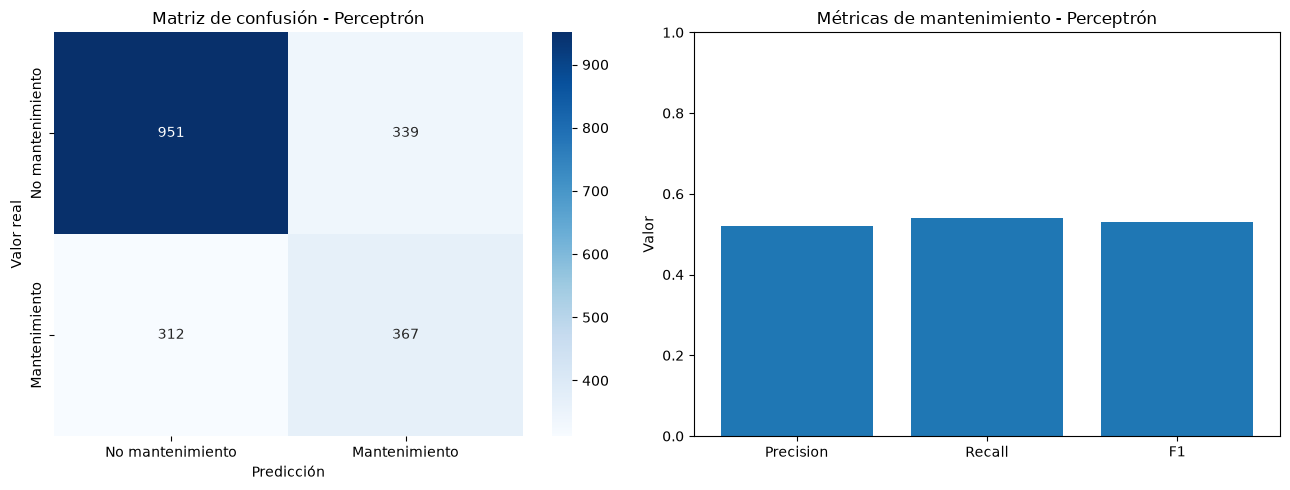

{'Precision': 0.5198300283286119,
 'Recall': 0.540500736377025,
 'F1': 0.5299638989169675}

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_perceptron)

# Métricas de la clase mantenimiento
metricas_perceptron = {
    "Precision": precision_score(y_test, y_pred_perceptron),
    "Recall": recall_score(y_test, y_pred_perceptron),
    "F1": f1_score(y_test, y_pred_perceptron)
}

# Una figura con dos gráficos
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# -----------------------------
# Gráfico 1: Matriz de confusión
# -----------------------------
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - Perceptrón")

# -----------------------------
# Gráfico 2: Precision, Recall y F1
# -----------------------------
ax[1].bar(
    metricas_perceptron.keys(),
    metricas_perceptron.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - Perceptrón")

plt.tight_layout()
plt.show()

metricas_perceptron


## 10. Segundo modelo: Perceptrón Multicapa (MLP)

El segundo modelo evaluado será un Perceptrón Multicapa (MLP).

A diferencia del Perceptrón simple, el MLP incorpora una o más capas ocultas que permiten aprender relaciones no lineales entre las variables.

Esto resulta especialmente interesante para nuestro problema, ya que la ocurrencia de mantenimiento correctivo podría depender de combinaciones entre distintas características del equipo, su utilización y su historial.

El modelo será entrenado utilizando los mismos conjuntos de entrenamiento y prueba utilizados anteriormente, permitiendo comparar directamente sus resultados con el Perceptrón simple.

In [14]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(50,),
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Entrenamiento
mlp.fit(X_train_s, y_train)

# Predicción
y_pred_mlp = mlp.predict(X_test_s)

# Métricas
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

print("Baseline:", round(baseline, 3))
print("Accuracy MLP:", round(accuracy_mlp, 3))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_mlp))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_mlp,
        target_names=["No mantenimiento", "Mantenimiento"]
    )
)

Baseline: 0.655
Accuracy MLP: 0.733

Matriz de confusión:
[[1021  269]
 [ 257  422]]

Reporte de clasificación:
                  precision    recall  f1-score   support

No mantenimiento       0.80      0.79      0.80      1290
   Mantenimiento       0.61      0.62      0.62       679

        accuracy                           0.73      1969
       macro avg       0.70      0.71      0.71      1969
    weighted avg       0.73      0.73      0.73      1969



### Evaluación del MLP

El Perceptrón Multicapa obtuvo una exactitud de **73,3 %**, superando el baseline de **65,5 %** y mejorando el resultado obtenido anteriormente con el Perceptrón simple.

Para la clase correspondiente a mantenimiento correctivo, el modelo obtuvo:

- Precision: **61 %**
- Recall: **62 %**
- F1-score: **62 %**

De los 679 casos reales de mantenimiento presentes en el conjunto de prueba, el modelo logró detectar correctamente 422 y no logró identificar 257.

Los resultados muestran una mejora respecto del Perceptrón simple tanto en exactitud general como en la capacidad de detectar períodos que requirieron mantenimiento correctivo.

Esto sugiere que las relaciones entre las variables del dataset no son completamente lineales y que un modelo capaz de representar relaciones más complejas puede adaptarse mejor al problema.

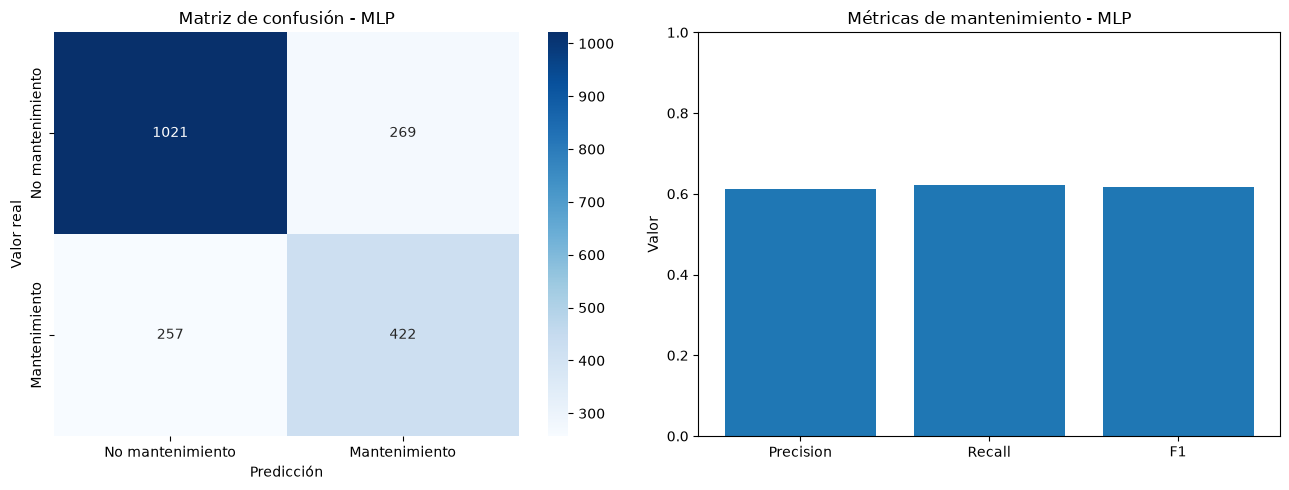

{'Precision': 0.6107091172214182,
 'Recall': 0.6215022091310751,
 'F1': 0.6160583941605839}

In [15]:
# Métricas del MLP
cm = confusion_matrix(y_test, y_pred_mlp)

metricas_mlp = {
    "Precision": precision_score(y_test, y_pred_mlp),
    "Recall": recall_score(y_test, y_pred_mlp),
    "F1": f1_score(y_test, y_pred_mlp)
}

# Creamos una figura con dos gráficos
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# -----------------------------
# Gráfico 1: Matriz de confusión
# -----------------------------
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - MLP")

# -----------------------------
# Gráfico 2: Precision, Recall y F1
# -----------------------------
ax[1].bar(
    metricas_mlp.keys(),
    metricas_mlp.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - MLP")

plt.tight_layout()
plt.show()

metricas_mlp


### Análisis de generalización del MLP

Luego de evaluar el modelo sobre el conjunto de prueba, se compara también su desempeño sobre los datos de entrenamiento.

El objetivo es determinar si existe una diferencia importante entre ambos resultados que pueda indicar un posible problema de overfitting.

In [16]:
accuracy_mlp_train = accuracy_score(
    y_train,
    mlp.predict(X_train_s)
)

diferencia_mlp = (
    accuracy_mlp_train - accuracy_mlp
)

print(
    "Accuracy Train:",
    round(accuracy_mlp_train, 3)
)

print(
    "Accuracy Test:",
    round(accuracy_mlp, 3)
)

print(
    "Diferencia:",
    round(diferencia_mlp, 3)
)

Accuracy Train: 0.831
Accuracy Test: 0.733
Diferencia: 0.098


### Ajuste del MLP

Para intentar mejorar la capacidad de generalización del MLP se evaluarán distintas configuraciones del modelo.

Siguiendo el procedimiento trabajado en clase, se compararán diferentes funciones de activación (`relu`, `tanh` y `logistic`) y distintos valores de regularización (`alpha`).

Para cada configuración se analizará su comportamiento sobre entrenamiento y prueba, junto con las métricas correspondientes a la clase de mantenimiento correctivo.

In [17]:
resultados_mlp = []

for activacion in ["relu", "tanh", "logistic"]:
    for alpha in [0.0001, 0.01]:

        modelo = MLPClassifier(
            hidden_layer_sizes=(50,),
            activation=activacion,
            alpha=alpha,
            solver="adam",
            max_iter=1000,
            random_state=RANDOM_STATE
        )

        modelo.fit(X_train_s, y_train)

        pred_train = modelo.predict(X_train_s)
        pred_test = modelo.predict(X_test_s)

        accuracy_train = accuracy_score(
            y_train,
            pred_train
        )

        accuracy_test = accuracy_score(
            y_test,
            pred_test
        )

        resultados_mlp.append({
            "Activación": activacion,
            "Alpha": alpha,
            "Accuracy Train": accuracy_train,
            "Accuracy Test": accuracy_test,
            "Diferencia": accuracy_train - accuracy_test,
            "Precision": precision_score(y_test, pred_test),
            "Recall": recall_score(y_test, pred_test),
            "F1": f1_score(y_test, pred_test)
        })

comparacion_mlp = pd.DataFrame(
    resultados_mlp
).sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

comparacion_mlp.round(3)

c:\Users\lgimenez\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Activación,Alpha,Accuracy Train,Accuracy Test,Diferencia,Precision,Recall,F1
0,relu,0.01,0.823,0.738,0.085,0.623,0.610,0.616
1,relu,0.00,0.831,0.733,0.098,0.611,0.622,0.616
2,logistic,0.01,0.918,0.713,0.205,0.586,0.574,0.580
3,logistic,0.00,0.940,0.709,0.231,0.581,0.563,0.571
4,tanh,0.01,0.964,0.702,0.261,0.572,0.546,0.559
5,tanh,0.00,0.976,0.689,0.287,0.550,0.546,0.548


### Selección de la configuración del MLP

La comparación muestra diferencias importantes entre las configuraciones evaluadas.

Las funciones `tanh` y `logistic` alcanzan valores muy elevados de Accuracy sobre entrenamiento, pero presentan una caída considerable al evaluarse sobre prueba, indicando un mayor grado de overfitting.

Las configuraciones con `relu` presentan un comportamiento considerablemente más estable.

Entre ellas, `relu` con `alpha=0.01` obtiene:

- Accuracy Train: **82,3 %**
- Accuracy Test: **73,8 %**
- Diferencia: **8,5 puntos porcentuales**
- Precision: **62,3 %**
- Recall: **61,0 %**
- F1-score: **61,6 %**

Esta configuración mantiene el mismo F1-score que el modelo original, mejora ligeramente el Accuracy y la Precision, y reduce la diferencia entre entrenamiento y prueba.

Por este motivo, se selecciona `relu` con `alpha=0.01` como configuración final del MLP.


In [18]:
mlp_ajustado = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation="relu",
    alpha=0.01,
    solver="adam",
    max_iter=1000,
    random_state=RANDOM_STATE
)

mlp_ajustado.fit(
    X_train_s,
    y_train
)

y_pred_mlp_ajustado = mlp_ajustado.predict(
    X_test_s
)

accuracy_mlp_ajustado = accuracy_score(
    y_test,
    y_pred_mlp_ajustado
)

precision_mlp_ajustado = precision_score(
    y_test,
    y_pred_mlp_ajustado
)

recall_mlp_ajustado = recall_score(
    y_test,
    y_pred_mlp_ajustado
)

f1_mlp_ajustado = f1_score(
    y_test,
    y_pred_mlp_ajustado
)

print("Accuracy:", round(accuracy_mlp_ajustado, 3))
print("Precision:", round(precision_mlp_ajustado, 3))
print("Recall:", round(recall_mlp_ajustado, 3))
print("F1:", round(f1_mlp_ajustado, 3))

Accuracy: 0.738
Precision: 0.623
Recall: 0.61
F1: 0.616


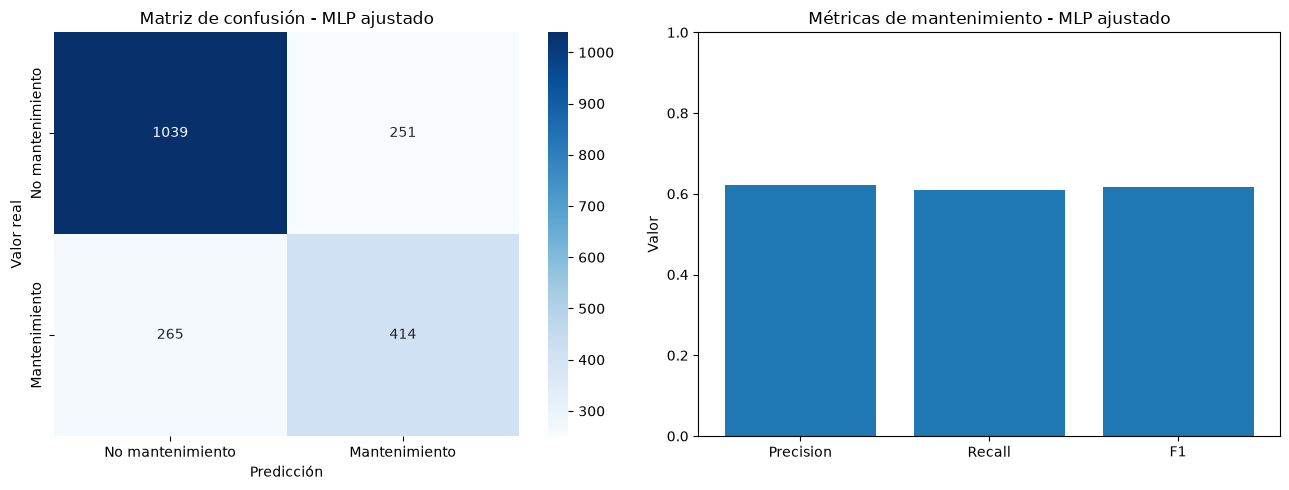

In [19]:
cm = confusion_matrix(
    y_test,
    y_pred_mlp_ajustado
)

metricas_mlp_ajustado = {
    "Precision": precision_mlp_ajustado,
    "Recall": recall_mlp_ajustado,
    "F1": f1_mlp_ajustado
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusión
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - MLP ajustado")

# Precision, Recall y F1
ax[1].bar(
    metricas_mlp_ajustado.keys(),
    metricas_mlp_ajustado.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - MLP ajustado")

plt.tight_layout()
plt.show()

### Conclusión del MLP

El MLP inicial presentó una diferencia de **9,8 puntos porcentuales** entre entrenamiento y prueba, mostrando cierto grado de overfitting.

Se evaluaron distintas configuraciones de función de activación y regularización.

Las funciones `tanh` y `logistic` mostraron un sobreajuste considerablemente mayor, mientras que las configuraciones con `relu` presentaron un comportamiento más estable.

La configuración seleccionada fue:

- Activación: `relu`
- Alpha: `0.01`

El modelo ajustado obtuvo:

- Accuracy: **73,8 %**
- Precision: **62,3 %**
- Recall: **61,0 %**
- F1-score: **61,6 %**

La diferencia entre entrenamiento y prueba se redujo de **9,8 a 8,5 puntos porcentuales**.

Por lo tanto, el ajuste permitió mejorar ligeramente la capacidad de generalización del modelo, aunque todavía se observa cierta diferencia entre su desempeño sobre entrenamiento y prueba.

## 11. Tercer modelo: Regresión Logística

Como tercer modelo se utilizará Regresión Logística.

A pesar de su nombre, la Regresión Logística puede utilizarse como un modelo de clasificación binaria.

En nuestro problema, el modelo buscará estimar la probabilidad de que una observación pertenezca a la clase de mantenimiento correctivo a partir de las variables predictoras disponibles.

Este modelo permitirá incorporar otro clasificador lineal a la comparación y evaluar si presenta mejores resultados que el Perceptrón simple y el Perceptrón Multicapa.

In [20]:
from sklearn.linear_model import LogisticRegression

logistica = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Entrenamiento
logistica.fit(X_train_s, y_train)

# Predicción
y_pred_logistica = logistica.predict(X_test_s)

# Métricas
accuracy_logistica = accuracy_score(
    y_test,
    y_pred_logistica
)

print("Baseline:", round(baseline, 3))
print("Accuracy Regresión Logística:", round(accuracy_logistica, 3))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_logistica))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_logistica,
        target_names=["No mantenimiento", "Mantenimiento"]
    )
)

Baseline: 0.655
Accuracy Regresión Logística: 0.75

Matriz de confusión:
[[1039  251]
 [ 242  437]]

Reporte de clasificación:
                  precision    recall  f1-score   support

No mantenimiento       0.81      0.81      0.81      1290
   Mantenimiento       0.64      0.64      0.64       679

        accuracy                           0.75      1969
       macro avg       0.72      0.72      0.72      1969
    weighted avg       0.75      0.75      0.75      1969



### Evaluación de la Regresión Logística

La Regresión Logística obtuvo una exactitud de **75 %**, superando el baseline de **65,5 %** y mejorando los resultados obtenidos con el Perceptrón simple y el Perceptrón Multicapa.

Para la clase correspondiente a mantenimiento correctivo, el modelo obtuvo:

- Precision: **64 %**
- Recall: **64 %**
- F1-score: **64 %**

De los 679 casos reales de mantenimiento presentes en el conjunto de prueba, el modelo logró detectar correctamente 437 y no logró identificar 242.

Hasta este punto, la Regresión Logística presenta el mejor desempeño general entre los modelos evaluados.

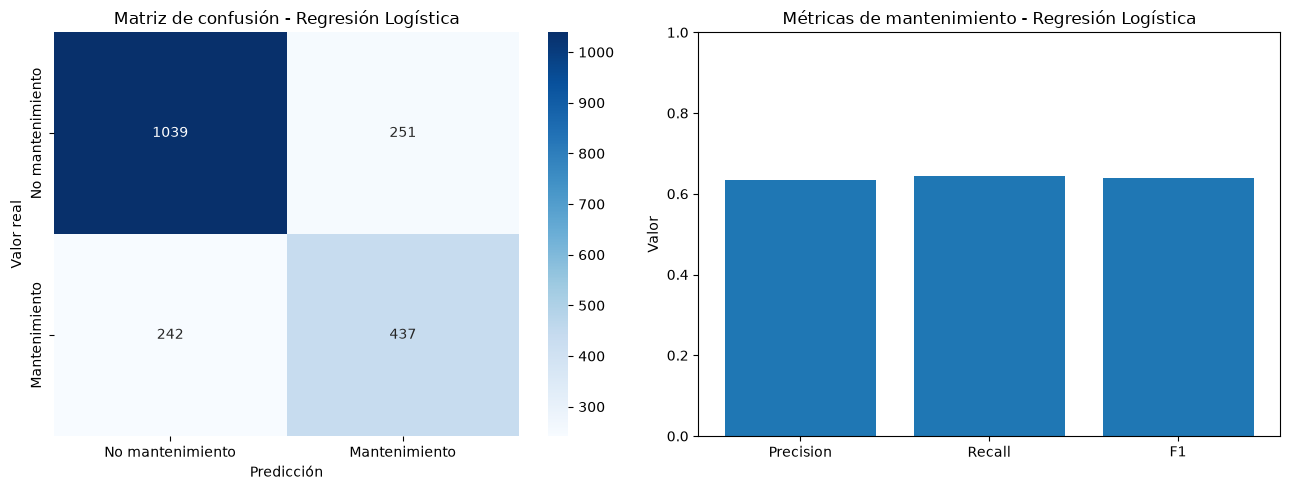

In [21]:
cm = confusion_matrix(y_test, y_pred_logistica)

metricas_logistica = {
    "Precision": precision_score(y_test, y_pred_logistica),
    "Recall": recall_score(y_test, y_pred_logistica),
    "F1": f1_score(y_test, y_pred_logistica)
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusión
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - Regresión Logística")

# Precision, Recall y F1
ax[1].bar(
    metricas_logistica.keys(),
    metricas_logistica.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - Regresión Logística")

plt.tight_layout()
plt.show()


### Análisis de generalización de la Regresión Logística

Luego de evaluar la Regresión Logística sobre el conjunto de prueba, se compara su desempeño con el obtenido sobre los datos de entrenamiento.

El objetivo es verificar si existe una diferencia importante entre ambos resultados y determinar si el modelo presenta indicios de overfitting.


In [22]:
accuracy_logistica_train = accuracy_score(
    y_train,
    logistica.predict(X_train_s)
)

diferencia_logistica = (
    accuracy_logistica_train
    - accuracy_logistica
)

print(
    "Accuracy Train:",
    round(accuracy_logistica_train, 3)
)

print(
    "Accuracy Test:",
    round(accuracy_logistica, 3)
)

print(
    "Diferencia:",
    round(diferencia_logistica, 3)
)

Accuracy Train: 0.752
Accuracy Test: 0.75
Diferencia: 0.003


**Conclusión:** la Regresión Logística obtiene un Accuracy de **75,2 %** sobre entrenamiento y **75,0 %** sobre prueba.

La diferencia de solamente **0,3 puntos porcentuales** indica que el modelo mantiene prácticamente el mismo desempeño frente a observaciones que no fueron utilizadas durante el entrenamiento.

Por lo tanto, no se observan indicios relevantes de overfitting.

Además, el modelo obtuvo sobre la clase de mantenimiento correctivo:

- Precision: **63,5 %**
- Recall: **64,4 %**
- F1-score: **63,9 %**

A diferencia del MLP, la Regresión Logística presenta una muy buena estabilidad entre entrenamiento y prueba, por lo que no resulta necesario realizar ajustes orientados específicamente a reducir overfitting.

La configuración actual se conservará como modelo final de Regresión Logística para la comparación posterior.

## 12. Cuarto modelo: Árbol de Decisión

Como cuarto modelo se utilizará un Árbol de Decisión.

A diferencia de los modelos lineales evaluados anteriormente, un árbol de decisión aprende reglas sucesivas sobre las variables predictoras para separar las observaciones entre las diferentes clases.

Esto permite representar relaciones no lineales y combinaciones entre variables sin necesidad de definirlas manualmente.

El modelo será evaluado utilizando el mismo conjunto de prueba y las mismas métricas utilizadas anteriormente.

In [23]:
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

arbol.fit(X_train, y_train)

y_pred_arbol = arbol.predict(X_test)

accuracy_arbol = accuracy_score(
    y_test,
    y_pred_arbol
)

print("Baseline:", round(baseline, 3))
print("Accuracy Árbol:", round(accuracy_arbol, 3))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_arbol))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_arbol,
        target_names=["No mantenimiento", "Mantenimiento"]
    )
)

Baseline: 0.655
Accuracy Árbol: 0.69

Matriz de confusión:
[[985 305]
 [305 374]]

Reporte de clasificación:
                  precision    recall  f1-score   support

No mantenimiento       0.76      0.76      0.76      1290
   Mantenimiento       0.55      0.55      0.55       679

        accuracy                           0.69      1969
       macro avg       0.66      0.66      0.66      1969
    weighted avg       0.69      0.69      0.69      1969



### Evaluación del Árbol de Decisión

El Árbol de Decisión obtuvo una exactitud de **69 %**, superando el baseline de **65,5 %**, aunque con un desempeño inferior al MLP y a la Regresión Logística.

Para la clase correspondiente a mantenimiento correctivo obtuvo:

- Precision: **55 %**
- Recall: **55 %**
- F1-score: **55 %**

De los 679 casos reales de mantenimiento presentes en el conjunto de prueba, el modelo identificó correctamente 374 y no logró detectar 305.

En su configuración inicial, el Árbol de Decisión no mejora los resultados obtenidos por los mejores modelos evaluados hasta el momento.

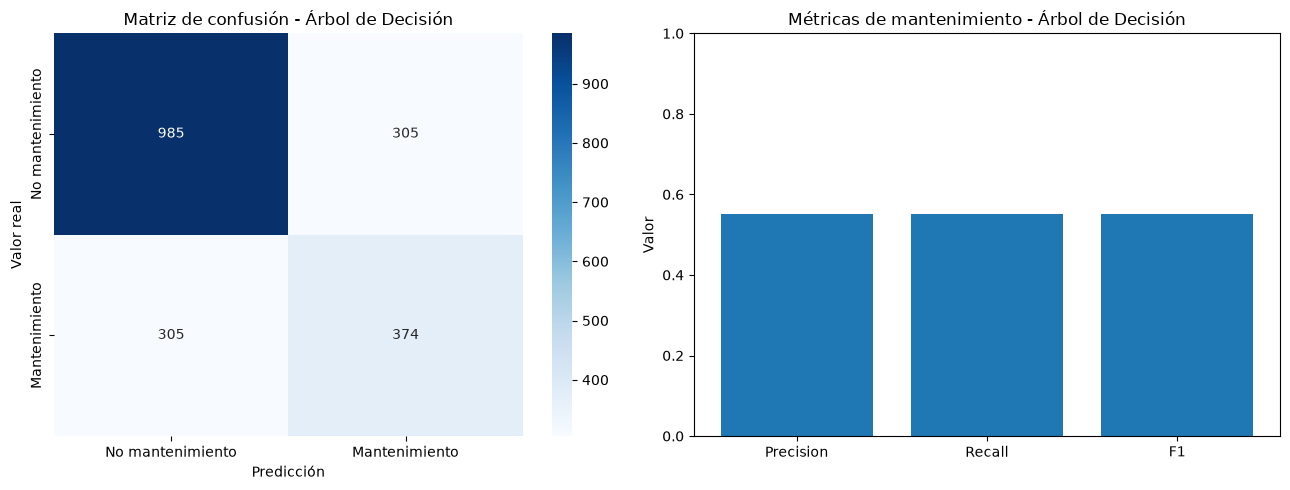

In [24]:
cm = confusion_matrix(y_test, y_pred_arbol)

metricas_arbol = {
    "Precision": precision_score(y_test, y_pred_arbol),
    "Recall": recall_score(y_test, y_pred_arbol),
    "F1": f1_score(y_test, y_pred_arbol)
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusión
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - Árbol de Decisión")

# Precision, Recall y F1
ax[1].bar(
    metricas_arbol.keys(),
    metricas_arbol.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - Árbol de Decisión")

plt.tight_layout()
plt.show()

### Análisis de generalización del Árbol de Decisión

### Detección de overfitting

Luego de evaluar el Árbol de Decisión sobre el conjunto de prueba, analizamos también su desempeño sobre los datos utilizados durante el entrenamiento.

El objetivo es verificar si existe una diferencia importante entre ambos resultados.

Un modelo que obtiene un desempeño muy elevado sobre entrenamiento pero disminuye considerablemente sobre prueba puede estar presentando **overfitting**, es decir, un ajuste excesivo a los datos utilizados para aprender.

In [25]:
# Accuracy sobre entrenamiento
y_pred_arbol_train = arbol.predict(X_train)

accuracy_arbol_train = accuracy_score(
    y_train,
    y_pred_arbol_train
)

# Accuracy sobre prueba
accuracy_arbol_test = accuracy_score(
    y_test,
    y_pred_arbol
)

# Diferencia entre ambos
diferencia_arbol = (
    accuracy_arbol_train - accuracy_arbol_test
)

print(
    "Accuracy Train:",
    round(accuracy_arbol_train, 3)
)

print(
    "Accuracy Test:",
    round(accuracy_arbol_test, 3)
)

print(
    "Diferencia Train - Test:",
    round(diferencia_arbol, 3)
)

Accuracy Train: 0.998
Accuracy Test: 0.69
Diferencia Train - Test: 0.307


**Conclusión:** el Árbol de Decisión alcanza aproximadamente **99,8 %** de Accuracy sobre entrenamiento pero solamente **69,0 %** sobre prueba.

La diferencia de aproximadamente **30,7 puntos porcentuales** indica un claro caso de overfitting.

El árbol se está ajustando excesivamente a las observaciones utilizadas durante el entrenamiento y pierde capacidad de generalización frente a datos que no fueron utilizados para entrenarlo.

Para reducir este problema se limitará la complejidad del árbol mediante el hiperparámetro `max_depth`.

### Ajuste de la profundidad del árbol

Una de las formas de controlar la complejidad de un Árbol de Decisión es limitar su profundidad máxima.

El hiperparámetro `max_depth` determina cuántos niveles de decisiones puede desarrollar el árbol.

Un árbol sin restricciones puede continuar realizando divisiones hasta adaptarse excesivamente a los datos de entrenamiento.

Por este motivo se evaluarán diferentes valores de `max_depth`, comparando el desempeño sobre entrenamiento y prueba y observando especialmente las métricas correspondientes a mantenimiento correctivo.

In [26]:
profundidades = [2, 3, 4, 5, 6, 8, 10, 15]

resultados_arbol = []

for profundidad in profundidades:

    modelo = DecisionTreeClassifier(
        max_depth=profundidad,
        random_state=RANDOM_STATE
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados_arbol.append({
        "max_depth": profundidad,

        "Accuracy Train": accuracy_score(
            y_train,
            pred_train
        ),

        "Accuracy Test": accuracy_score(
            y_test,
            pred_test
        ),

        "Recall": recall_score(
            y_test,
            pred_test
        ),

        "F1": f1_score(
            y_test,
            pred_test
        )
    })

comparacion_arbol = pd.DataFrame(
    resultados_arbol
)

comparacion_arbol.round(3)

,max_depth,Accuracy Train,Accuracy Test,Recall,F1
0,2,0.684,0.675,0.873,0.650
1,3,0.720,0.719,0.676,0.624
2,4,0.723,0.719,0.676,0.624
3,5,0.730,0.713,0.813,0.661
4,6,0.744,0.721,0.672,0.624
5,8,0.777,0.726,0.649,0.621
6,10,0.811,0.728,0.666,0.628
7,15,0.882,0.705,0.589,0.580


### Selección de la profundidad

Los resultados muestran que limitar la profundidad reduce considerablemente el overfitting del modelo.

La configuración `max_depth=5` presenta un comportamiento especialmente interesante:

- Accuracy Train: **73,0 %**
- Accuracy Test: **71,3 %**
- Recall: **81,3 %**
- F1-score: **66,1 %**

Aunque existen configuraciones con un Accuracy ligeramente superior, `max_depth=5` presenta el mayor F1-score entre las alternativas evaluadas y un Recall considerablemente elevado.

Dado que en este proyecto resulta especialmente importante detectar correctamente los casos de mantenimiento correctivo, se selecciona `max_depth=5` como configuración ajustada del Árbol de Decisión.

In [27]:
arbol_ajustado = DecisionTreeClassifier(
    max_depth=5,
    random_state=RANDOM_STATE
)

# Entrenamiento
arbol_ajustado.fit(
    X_train,
    y_train
)

# Predicciones finales del árbol ajustado
y_pred_arbol_ajustado = arbol_ajustado.predict(
    X_test
)

# Métricas finales
accuracy_arbol_ajustado = accuracy_score(
    y_test,
    y_pred_arbol_ajustado
)

precision_arbol_ajustado = precision_score(
    y_test,
    y_pred_arbol_ajustado
)

recall_arbol_ajustado = recall_score(
    y_test,
    y_pred_arbol_ajustado
)

f1_arbol_ajustado = f1_score(
    y_test,
    y_pred_arbol_ajustado
)

print(
    "Accuracy:",
    round(accuracy_arbol_ajustado, 3)
)

print(
    "Precision:",
    round(precision_arbol_ajustado, 3)
)

print(
    "Recall:",
    round(recall_arbol_ajustado, 3)
)

print(
    "F1:",
    round(f1_arbol_ajustado, 3)
)

Accuracy: 0.713
Precision: 0.557
Recall: 0.813
F1: 0.661


### Evaluación final del Árbol de Decisión ajustado

Luego de limitar la profundidad del árbol a `max_depth=5`, el modelo presenta un comportamiento considerablemente más equilibrado entre entrenamiento y prueba.

El modelo ajustado obtiene:

- Accuracy: **71,3 %**
- Precision: **55,7 %**
- Recall: **81,3 %**
- F1-score: **66,1 %**

El resultado más destacado es el Recall de 81,3 %, lo que indica que el modelo logra identificar aproximadamente 8 de cada 10 casos reales de mantenimiento correctivo.

Esta mejora se obtiene reduciendo considerablemente el overfitting presente en el árbol original.

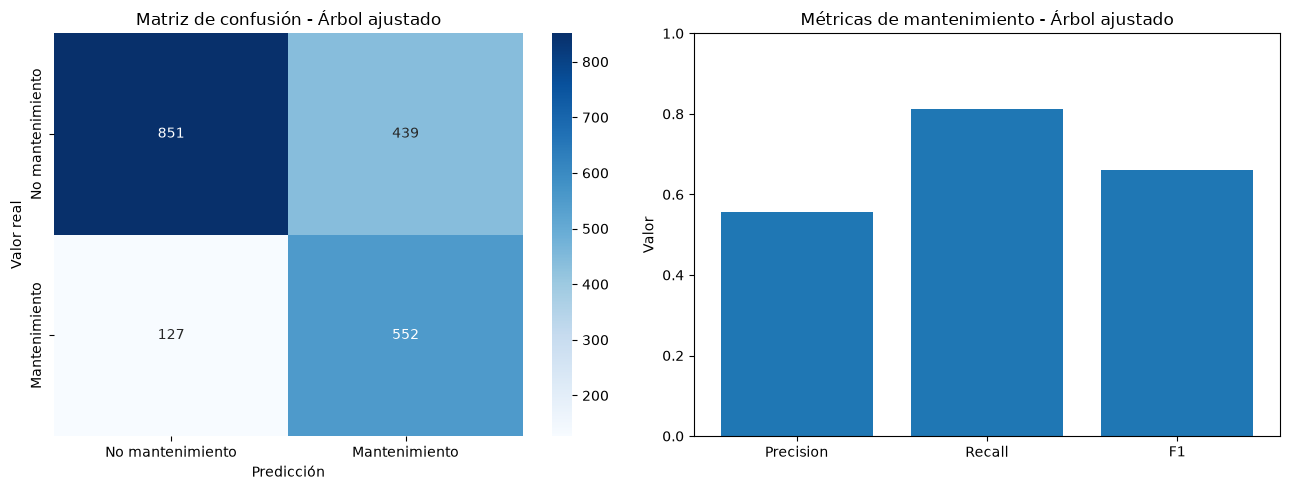

In [28]:
cm = confusion_matrix(
    y_test,
    y_pred_arbol_ajustado
)

metricas_arbol_ajustado = {
    "Precision": precision_arbol_ajustado,
    "Recall": recall_arbol_ajustado,
    "F1": f1_arbol_ajustado
}

fig, ax = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# Matriz de confusión
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No mantenimiento",
        "Mantenimiento"
    ],
    yticklabels=[
        "No mantenimiento",
        "Mantenimiento"
    ],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title(
    "Matriz de confusión - Árbol ajustado"
)

# Precision, Recall y F1
ax[1].bar(
    metricas_arbol_ajustado.keys(),
    metricas_arbol_ajustado.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title(
    "Métricas de mantenimiento - Árbol ajustado"
)

plt.tight_layout()
plt.show()

### Conclusión del Árbol de Decisión

El Árbol de Decisión original presentaba un fuerte overfitting, con un Accuracy de 99,8 % sobre entrenamiento y solamente 69,0 % sobre prueba.

La limitación de la profundidad máxima a cinco niveles permitió reducir considerablemente este problema:

- Accuracy Train: **73,0 %**
- Accuracy Test: **71,3 %**

Además, el Árbol ajustado alcanzó un Recall de **81,3 %** para mantenimiento correctivo, considerablemente superior al 55,1 % obtenido por el árbol original.

El ajuste muestra que aumentar la complejidad de un modelo no garantiza un mejor desempeño sobre datos nuevos. En este caso, reducir la complejidad permitió obtener un modelo con mayor capacidad de generalización y mayor capacidad para detectar casos reales de mantenimiento.

Aunque su Accuracy es inferior al de la Regresión Logística, su elevado Recall lo convierte en un modelo especialmente interesante cuando el objetivo principal es minimizar la cantidad de fallas que no son detectadas.

## 13. Quinto modelo: Random Forest

Como quinto modelo se utilizará Random Forest.

Random Forest es un modelo basado en múltiples árboles de decisión. Cada árbol aprende diferentes patrones presentes en los datos y sus resultados se combinan para realizar la clasificación final.

El objetivo es evaluar si la combinación de múltiples árboles permite obtener una mejor capacidad de generalización que un único Árbol de Decisión.

El modelo será evaluado utilizando el mismo conjunto de prueba y las mismas métricas utilizadas en los modelos anteriores.

In [29]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Baseline:", round(baseline, 3))
print("Accuracy Random Forest:", round(accuracy_rf, 3))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No mantenimiento", "Mantenimiento"]
    )
)

Baseline: 0.655
Accuracy Random Forest: 0.73

Matriz de confusión:
[[1026  264]
 [ 268  411]]

Reporte de clasificación:
                  precision    recall  f1-score   support

No mantenimiento       0.79      0.80      0.79      1290
   Mantenimiento       0.61      0.61      0.61       679

        accuracy                           0.73      1969
       macro avg       0.70      0.70      0.70      1969
    weighted avg       0.73      0.73      0.73      1969



### Evaluación de Random Forest

Random Forest obtuvo una exactitud de **73 %**, superando el baseline de **65,5 %** y mejorando considerablemente el resultado obtenido con un único Árbol de Decisión.

Para la clase correspondiente a mantenimiento correctivo obtuvo:

- Precision: **61 %**
- Recall: **61 %**
- F1-score: **61 %**

De los 679 casos reales de mantenimiento presentes en el conjunto de prueba, el modelo logró identificar correctamente 411 y no logró detectar 268.

El resultado muestra que la combinación de múltiples árboles mejora el desempeño respecto de un único Árbol de Decisión. Sin embargo, en su configuración inicial, Random Forest no supera los resultados obtenidos por el MLP ni por la Regresión Logística.

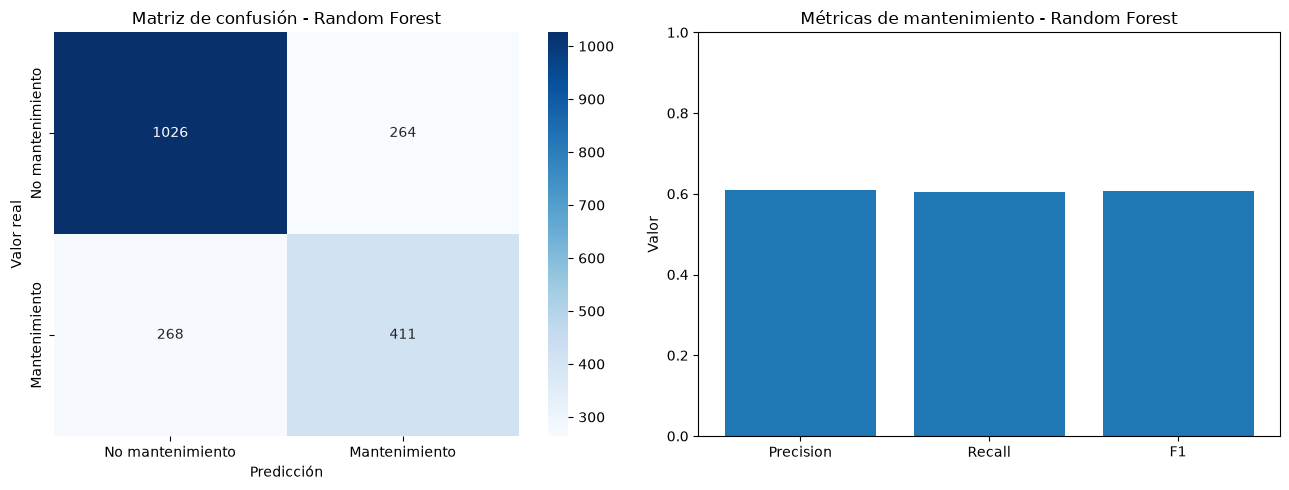

In [30]:
cm = confusion_matrix(y_test, y_pred_rf)

metricas_rf = {
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1": f1_score(y_test, y_pred_rf)
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Matriz de confusión
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title("Matriz de confusión - Random Forest")

# Precision, Recall y F1
ax[1].bar(
    metricas_rf.keys(),
    metricas_rf.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas de mantenimiento - Random Forest")

plt.tight_layout()
plt.show()

### Análisis de generalización de Random Forest

Luego de evaluar Random Forest sobre el conjunto de prueba, se compara su desempeño con el obtenido sobre los datos de entrenamiento.

El objetivo es determinar si el modelo mantiene su capacidad predictiva sobre observaciones que no fueron utilizadas durante el aprendizaje.


In [31]:
accuracy_rf_train = accuracy_score(
    y_train,
    random_forest.predict(X_train)
)

diferencia_rf = (
    accuracy_rf_train - accuracy_rf
)

print(
    "Accuracy Train:",
    round(accuracy_rf_train, 3)
)

print(
    "Accuracy Test:",
    round(accuracy_rf, 3)
)

print(
    "Diferencia:",
    round(diferencia_rf, 3)
)

Accuracy Train: 0.998
Accuracy Test: 0.73
Diferencia: 0.268


**Conclusión:** Random Forest obtiene un Accuracy de aproximadamente **99,8 %** sobre entrenamiento y **73,0 %** sobre prueba.

La diferencia de aproximadamente **26,8 puntos porcentuales** indica un fuerte grado de overfitting.

El modelo se adapta casi perfectamente a los datos utilizados durante el entrenamiento, pero pierde una parte importante de su desempeño frente a observaciones nuevas.

Por este motivo, antes de considerar Random Forest como modelo definitivo será necesario reducir su complejidad.

### Ajuste de la profundidad de Random Forest

Para reducir el overfitting se evaluarán diferentes valores de `max_depth`.

Este hiperparámetro limita la profundidad máxima de cada árbol que forma parte del bosque.

El objetivo es reducir la diferencia entre entrenamiento y prueba manteniendo una buena capacidad para detectar los casos de mantenimiento correctivo.

In [32]:
profundidades_rf = [3, 5, 8, 10, 15, None]

resultados_rf = []

for profundidad in profundidades_rf:

    modelo = RandomForestClassifier(
        n_estimators=100,
        max_depth=profundidad,
        random_state=RANDOM_STATE
    )

    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    accuracy_train = accuracy_score(
        y_train,
        pred_train
    )

    accuracy_test = accuracy_score(
        y_test,
        pred_test
    )

    resultados_rf.append({
        "max_depth": str(profundidad),
        "Accuracy Train": accuracy_train,
        "Accuracy Test": accuracy_test,
        "Diferencia": accuracy_train - accuracy_test,
        "Precision": precision_score(y_test, pred_test),
        "Recall": recall_score(y_test, pred_test),
        "F1": f1_score(y_test, pred_test)
    })


comparacion_rf = pd.DataFrame(
    resultados_rf
)

comparacion_rf.round(3)

,max_depth,Accuracy Train,Accuracy Test,Diferencia,Precision,Recall,F1
0,3,0.673,0.662,0.011,0.584,0.066,0.119
1,5,0.740,0.724,0.016,0.623,0.507,0.559
2,8,0.790,0.749,0.041,0.625,0.679,0.651
3,10,0.812,0.751,0.061,0.625,0.694,0.657
4,15,0.907,0.742,0.165,0.614,0.677,0.644
5,None,0.998,0.730,0.268,0.609,0.605,0.607


### Selección de la configuración de Random Forest

Los resultados muestran que limitar la profundidad de los árboles reduce considerablemente el overfitting del modelo.

El Random Forest original, sin límite de profundidad, presentaba:

- Accuracy Train: **99,8 %**
- Accuracy Test: **73,0 %**
- Diferencia: **26,8 puntos porcentuales**

Entre las configuraciones evaluadas, `max_depth=10` presenta el mejor comportamiento general:

- Accuracy Train: **81,2 %**
- Accuracy Test: **75,1 %**
- Diferencia: **6,1 puntos porcentuales**
- Precision: **62,5 %**
- Recall: **69,4 %**
- F1-score: **65,7 %**

Esta configuración mejora el desempeño sobre prueba y reduce considerablemente la diferencia entre entrenamiento y prueba.

Por este motivo, se selecciona `max_depth=10` como configuración final de Random Forest.

In [33]:
random_forest_ajustado = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=RANDOM_STATE
)

random_forest_ajustado.fit(
    X_train,
    y_train
)

y_pred_rf_ajustado = random_forest_ajustado.predict(
    X_test
)

accuracy_rf_ajustado = accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

precision_rf_ajustado = precision_score(
    y_test,
    y_pred_rf_ajustado
)

recall_rf_ajustado = recall_score(
    y_test,
    y_pred_rf_ajustado
)

f1_rf_ajustado = f1_score(
    y_test,
    y_pred_rf_ajustado
)

print("Accuracy:", round(accuracy_rf_ajustado, 3))
print("Precision:", round(precision_rf_ajustado, 3))
print("Recall:", round(recall_rf_ajustado, 3))
print("F1:", round(f1_rf_ajustado, 3))

Accuracy: 0.751
Precision: 0.625
Recall: 0.694
F1: 0.657


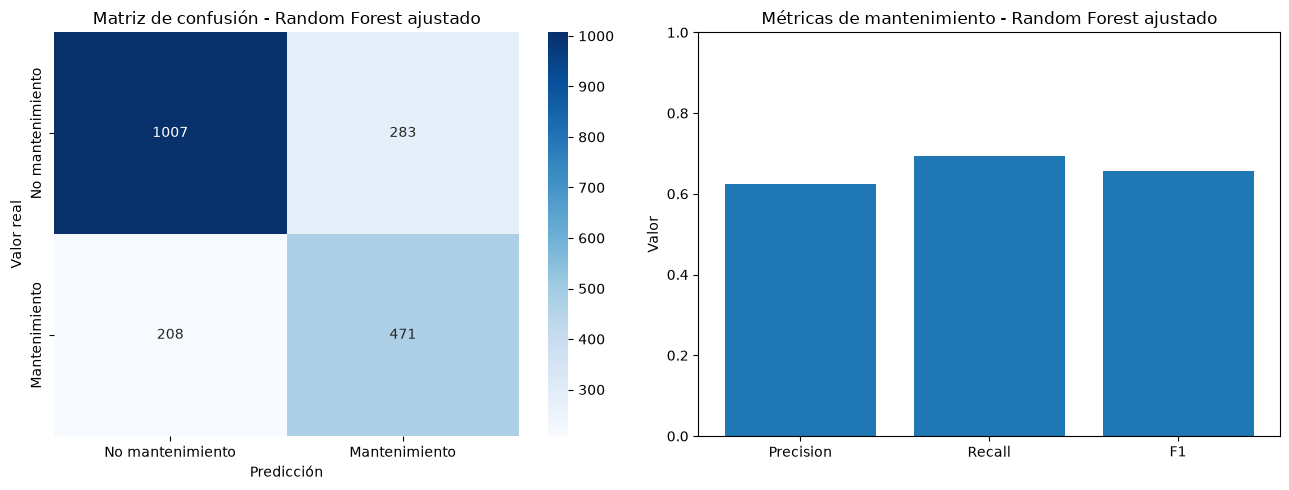

In [34]:
cm = confusion_matrix(
    y_test,
    y_pred_rf_ajustado
)

metricas_rf_ajustado = {
    "Precision": precision_rf_ajustado,
    "Recall": recall_rf_ajustado,
    "F1": f1_rf_ajustado
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mantenimiento", "Mantenimiento"],
    yticklabels=["No mantenimiento", "Mantenimiento"],
    ax=ax[0]
)

ax[0].set_xlabel("Predicción")
ax[0].set_ylabel("Valor real")
ax[0].set_title(
    "Matriz de confusión - Random Forest ajustado"
)

ax[1].bar(
    metricas_rf_ajustado.keys(),
    metricas_rf_ajustado.values()
)

ax[1].set_ylim(0, 1)
ax[1].set_ylabel("Valor")
ax[1].set_title(
    "Métricas de mantenimiento - Random Forest ajustado"
)

plt.tight_layout()
plt.show()

### Conclusión de Random Forest

El Random Forest inicial presentó un fuerte overfitting, con un Accuracy de **99,8 %** sobre entrenamiento y **73,0 %** sobre prueba.

Al limitar la profundidad máxima de los árboles a 10 niveles, el modelo redujo considerablemente esta diferencia y mejoró su desempeño sobre observaciones nuevas.

El modelo ajustado obtuvo:

- Accuracy: **75,1 %**
- Precision: **62,5 %**
- Recall: **69,4 %**
- F1-score: **65,7 %**

La diferencia entre entrenamiento y prueba disminuyó de **26,8 a 6,1 puntos porcentuales**.

Por lo tanto, la reducción de la complejidad permitió obtener un Random Forest con mejor capacidad de generalización y mayor capacidad para detectar los casos de mantenimiento correctivo.

## 14. Comparación final de los modelos

Una vez evaluada la capacidad de generalización y realizados los ajustes necesarios, se comparan las versiones finales de los modelos supervisados.

La comparación considera:

- Accuracy: porcentaje total de predicciones correctas.
- Precision: proporción de alertas de mantenimiento que fueron correctas.
- Recall: proporción de mantenimientos reales que el modelo logró detectar.
- F1-score: equilibrio entre Precision y Recall.

Debido al objetivo del proyecto, resulta especialmente importante considerar Recall y F1, ya que no detectar un mantenimiento correctivo puede ser más relevante que generar una alerta adicional.


In [37]:
resultados_finales = pd.DataFrame({
    "Modelo": [
        "Perceptrón",
        "MLP ajustado",
        "Regresión Logística",
        "Árbol de decisión ajustado",
        "Random Forest ajustado"
    ],

    "Accuracy": [
        accuracy_perceptron,
        accuracy_mlp_ajustado,
        accuracy_logistica,
        accuracy_arbol_ajustado,
        accuracy_rf_ajustado
    ],

    "Precision": [
        precision_score(y_test, y_pred_perceptron),
        precision_mlp_ajustado,
        precision_score(y_test, y_pred_logistica),
        precision_arbol_ajustado,
        precision_rf_ajustado
    ],

    "Recall": [
        recall_score(y_test, y_pred_perceptron),
        recall_mlp_ajustado,
        recall_score(y_test, y_pred_logistica),
        recall_arbol_ajustado,
        recall_rf_ajustado
    ],

    "F1": [
        f1_score(y_test, y_pred_perceptron),
        f1_mlp_ajustado,
        f1_score(y_test, y_pred_logistica),
        f1_arbol_ajustado,
        f1_rf_ajustado
    ]
})

resultados_finales.round(3)

,Modelo,Accuracy,Precision,Recall,F1
0,Perceptrón,0.669,0.520,0.541,0.530
1,MLP ajustado,0.738,0.623,0.610,0.616
2,Regresión Logística,0.750,0.635,0.644,0.639
3,Árbol de decisión ajustado,0.713,0.557,0.813,0.661
4,Random Forest ajustado,0.751,0.625,0.694,0.657


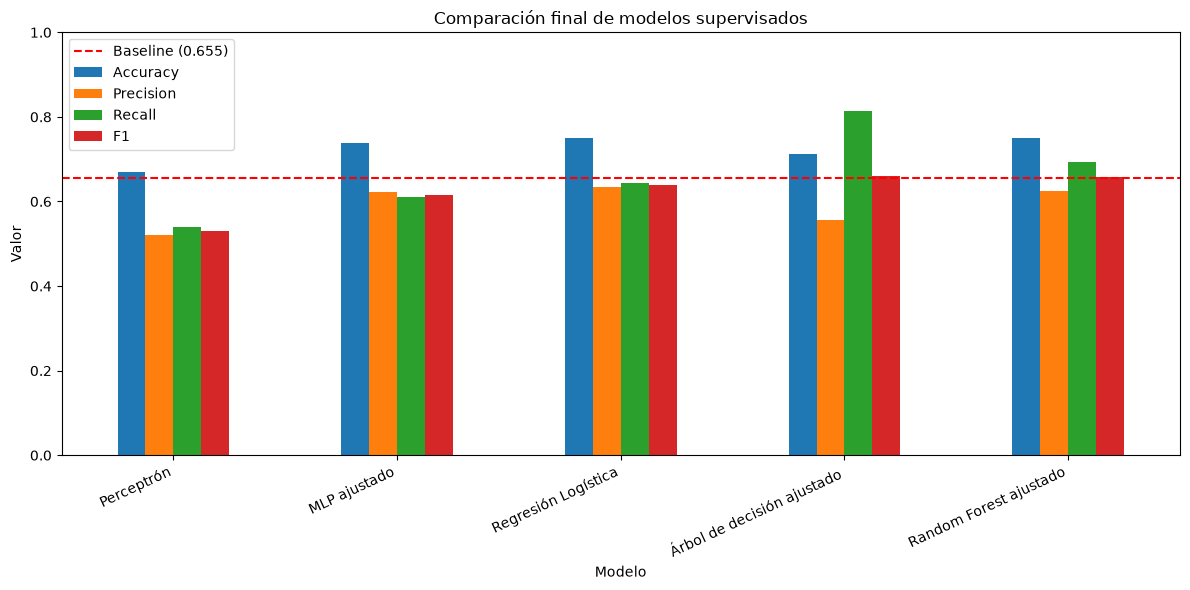

In [38]:
resultados_plot = resultados_finales.set_index(
    "Modelo"
)

resultados_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(
    y=baseline,
    color="red",
    linestyle="--",
    label=f"Baseline ({baseline:.3f})"
)

plt.ylim(0, 1)
plt.ylabel("Valor")
plt.title("Comparación final de modelos supervisados")
plt.xticks(rotation=25, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

## 15. Selección del modelo y aplicación operativa

Luego de evaluar y ajustar los distintos modelos supervisados, se observa que no existe un único modelo que domine todas las métricas.

Random Forest ajustado presenta el mejor Accuracy general, con **75,1 %**, junto con un Recall de **69,4 %** y un F1-score de **65,7 %**, ofreciendo un comportamiento equilibrado.

El Árbol de Decisión ajustado, por su parte, alcanza un Recall de **81,3 %**, logrando detectar aproximadamente 8 de cada 10 casos reales de mantenimiento correctivo. Como contrapartida, presenta una Precision menor (**55,7 %**), lo que implica una mayor cantidad de falsos positivos.

Sin embargo, en el contexto de mantenimiento estos falsos positivos no necesariamente representan un resultado negativo. Una alerta sobre un equipo que finalmente no requiere una reparación puede utilizarse como una oportunidad para realizar una revisión preventiva, consultar al conductor sobre comportamientos anormales y prestar mayor atención al estado del equipo antes de una operación.

Por este motivo, el costo de una falsa alarma puede ser considerablemente menor que el costo de no detectar una falla real.

Esta diferencia resulta especialmente importante en sistemas críticos del vehículo. Una falla no detectada en componentes como frenos, dirección, motor o sistemas eléctricos podría generar indisponibilidad del equipo o una falla durante la operación.

Como evolución futura del proyecto, el modelo podría ampliarse para no solamente estimar si un equipo presenta riesgo de requerir mantenimiento, sino también identificar **qué sistema presenta mayor probabilidad de falla**.

El dataset ya contiene fallas clasificadas por sistemas como motor, frenos, transmisión, sistema eléctrico, suspensión y otros componentes. Esto permitiría estudiar modelos específicos para cada tipo de falla. 

### Aplicación futura

Una posible aplicación operativa sería generar alertas del tipo:

> **"Este equipo presenta un riesgo elevado de requerir mantenimiento y el sistema con mayor riesgo estimado es frenos."**

Esta alerta no implicaría detener automáticamente el equipo ni afirmar que una falla ocurrirá con certeza.

Funcionaría como una herramienta de apoyo para priorizar inspecciones y mejorar la comunicación entre mantenimiento y operación.

Por ejemplo, ante una alerta relacionada con frenos, el personal de mantenimiento podría realizar una revisión prioritaria y consultar al conductor si observó síntomas como cambios en la respuesta del frenado, ruidos, vibraciones u otras anomalías.

De esta manera, el Machine Learning no reemplazaría el diagnóstico mecánico, sino que permitiría orientar la atención hacia los equipos con mayor riesgo estimado.

El objetivo final sería evolucionar desde un modelo que clasifica mantenimiento correctivo hacia un sistema de apoyo al mantenimiento predictivo capaz de:

1. identificar equipos con mayor riesgo;
2. estimar qué sistema podría estar comprometido;
3. priorizar inspecciones;
4. generar alertas tempranas para mantenimiento y operación;
5. reducir fallas operativas y detenciones no planificadas.